# Predicting End-of-Line Test Failures of Toroidal Transformers with RuleFit

**IT5514 Applied Machine Learning – Assignment**

**Goal:** predict, *before* the automated end-of-line (EOL) electrical test, whether a toroidal transformer will **fail its first test**. The model uses only upstream data: steel, annealing, winding and environment.

**Algorithm:** **RuleFit** (Friedman & Popescu, 2008), a *rule ensemble*. Candidate IF-THEN rules are generated from a randomised tree ensemble, and a sparse L1-regularised logistic model then keeps a few dozen of them. The result is a model engineers can read line by line. It was not covered in the lectures and is not deep learning. Logistic Regression, Random Forest and CatBoost (all from the course) serve as benchmarks.

Notebook outline
1. Data loading & raw-data quality audit
2. Cleaning
3. Exploratory data analysis
4. Leakage control & feature engineering
5. Time-based train / validation / test split
6. RuleFit: theory, implementation, model selection
7. Benchmarks from the course (Logistic Regression, Random Forest, CatBoost)
8. Final evaluation on the hold-out test period
9. Explainability (rules, Friedman importance, permutation importance, PDP/ICE, local explanations, comparison with SHAP)
10. Bias / robustness checks
11. Saving the model for the front-end

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
from catboost import CatBoostClassifier, Pool
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, f1_score, precision_score, recall_score, brier_score_loss)

from toroid_preprocess import (load_raw, clean, first_attempts, FeatureBuilder,
                               CAT_FEATURES, NUM_FEATURES, ENGINEERED, FEATURES, LEAKAGE_COLS)
from rulefit import RuleFitClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80, "display.width", 220, "display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
MODELS = Path("models"); MODELS.mkdir(exist_ok=True)
SEED = 42
DATA = Path("toroid_test_data.csv")

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

def scores(y, p):
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "Brier": brier_score_loss(y, p)}

D:\PERSONAL\02_Education\MSc\Sem 02\IT5514 - Applied Machine Learning\AML\Code\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data loading and raw-data quality audit

The file is a raw export joining MES traceability records with the test-station database: one row per EOL test attempt. Before any cleaning, we audit the problems typical of a shop-floor export.

In [2]:
raw = load_raw(DATA)
print(raw.shape)
raw.head(3).T.head(30)

(13007, 74)


,0,1,2
record_id,100000,100001,100002
serial_no,TT2509-000001,TT2509-000002,TT2509-000003
work_order,WO-25-0402,WO-25-0403,WO-25-0402
product_code,TT0500-230-2X18-I,TT1500-2X115-2X12-60-I,TT0500-230-2X18-I
rated_power_VA,500,1500,500
primary_config,230,2x115,230
secondary_config,2x18,2x12,2x18
frequency_Hz,50,60,50
application_segment,IND,IND,IND
steel_grade,M6,M6,M6


In [3]:
audit = {
    "rows": len(raw),
    "exact duplicate rows": int(raw.duplicated().sum()),
    "retest rows (test_attempt = 2)": int((raw.test_attempt == 2).sum()),
    "unique serial numbers": raw.serial_no.nunique(),
    "test_ts in DD/MM/YYYY format (TS-02)": int(raw.test_ts.str.contains("/").sum()),
    "shift label variants": sorted(raw["shift"].dropna().unique().tolist()),
    "core_deburred variants": sorted(raw.core_deburred.fillna("<blank>").unique().tolist()),
    "lower-case product codes": int((raw.product_code != raw.product_code.str.upper()).sum()),
    "anneal_peak_temp_C == 0 (thermocouple fault)": int((raw.anneal_peak_temp_C == 0).sum()),
    "winding RH = 0 or 999.9 (sensor fault)": int(raw.winding_area_RH_pct.isin([0, 999.9]).sum()),
    "ir_Mohm = 'OVR' (meter over-range)": int((raw.ir_Mohm == "OVR").sum()),
}
pd.Series(audit, name="value").to_frame()

,value
rows,13007
exact duplicate rows,14
retest rows (test_attempt = 2),229
unique serial numbers,12765
test_ts in DD/MM/YYYY format (TS-02),5177
shift label variants,"[ A, B, C, A, A , B, B , C, C , Shift A, Shift B, Shift C, a, b, c]"
core_deburred variants,"[<blank>, N, No, Y, Yes, n, y]"
lower-case product codes,77
anneal_peak_temp_C == 0 (thermocouple fault),9
winding RH = 0 or 999.9 (sensor fault),125


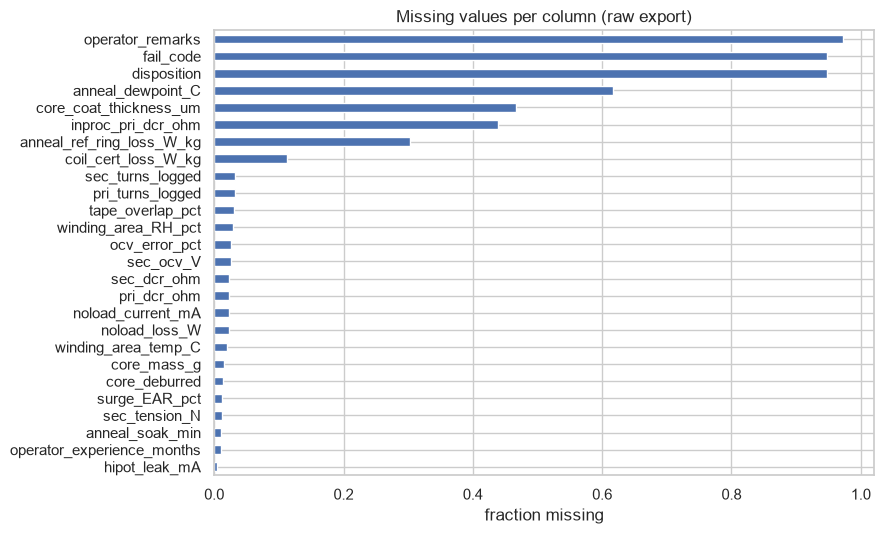

In [4]:
miss = raw.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
plt.figure(figsize=(9, 5.5))
miss.plot.barh(color="#4C72B0"); plt.gca().invert_yaxis()
plt.xlabel("fraction missing"); plt.title("Missing values per column (raw export)")
savefig("01_missingness")

Most missingness is **structural** (missing not at random):
* `anneal_dewpoint_C`: the sensor was installed in April 2026.
* `core_coat_thickness_um`: only exists for epoxy-coated cores.
* `inproc_pri_dcr_ohm`: only the CNC winders have an in-process ohmmeter.
* `anneal_ref_ring_loss_W_kg`: about 30 % of batches were not sampled.
* Test-station columns: blank after a fail on TS-01, which stops on the first fail.

The RuleFit implementation sends missing values to a separate branch, so rules can say *"X is missing"* instead of relying on an imputed value.

## 2. Cleaning

`toroid_preprocess.clean()` applies the following:
* Drop exact duplicates.
* Harmonise categorical labels (`shift`, `core_deburred`, `product_code`, `wire_supplier`).
* Set sentinels to NaN (0 °C anneal temperature; RH of 0 or above 100 %).
* Fix core masses typed in mg.
* Turn `OVR` into a numeric ceiling.
* Parse both timestamp formats.

`first_attempts()` keeps the **first** test of each serial number, which is the modelling grain. Retests happen after rework, so they describe a different object.

In [5]:
df = clean(raw)
fa = first_attempts(df)
print(f"after de-duplication: {len(df):,} test records  ->  {len(fa):,} units (first attempts)")
print("shift:", sorted(df['shift'].unique()), "| core_deburred:", sorted(df.core_deburred.unique()))
print("unparsed test timestamps:", df.test_ts.isna().sum())
print(f"first-pass failure rate: {fa.y_fail.mean():.2%}")

after de-duplication: 12,993 test records  ->  12,765 units (first attempts)
shift: ['A', 'B', 'C'] | core_deburred: ['N', 'UNKNOWN', 'Y']
unparsed test timestamps: 0
first-pass failure rate: 5.17%


## 3. Exploratory data analysis

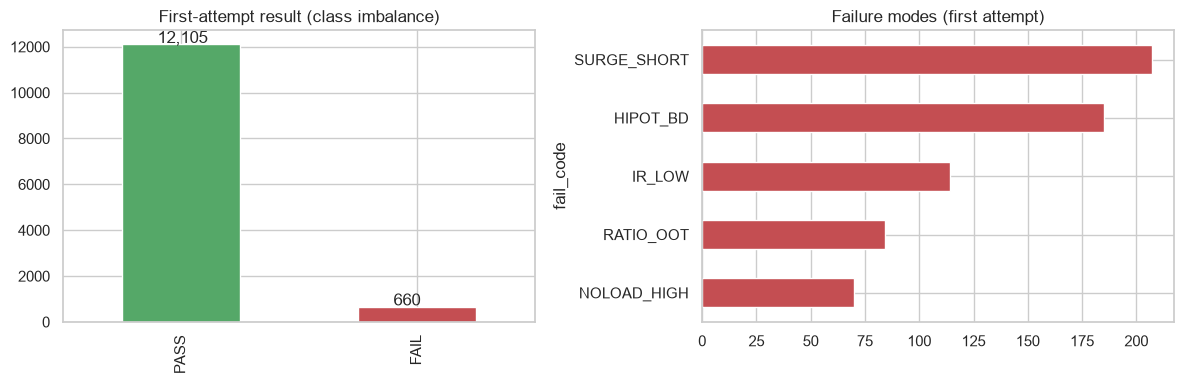

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
fa.result.value_counts().plot.bar(ax=ax[0], color=["#55A868", "#C44E52"])
ax[0].set_title("First-attempt result (class imbalance)"); ax[0].set_xlabel("")
for p in ax[0].patches: ax[0].annotate(f"{int(p.get_height()):,}", (p.get_x()+0.15, p.get_height()+60))
fa.loc[fa.y_fail == 1, "fail_code"].value_counts().plot.barh(ax=ax[1], color="#C44E52")
ax[1].set_title("Failure modes (first attempt)"); ax[1].invert_yaxis()
savefig("02_target")

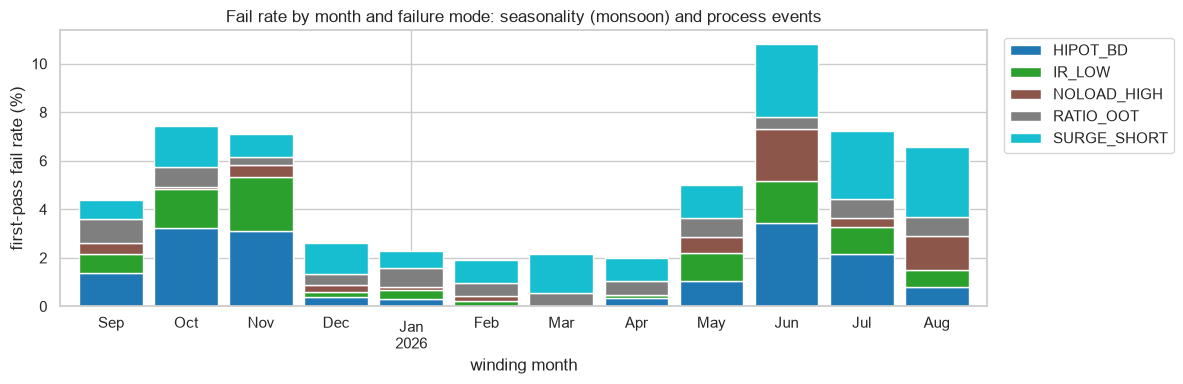

In [7]:
mode_m = pd.crosstab(fa.wind_end_ts.dt.to_period("M"), fa.fail_code, normalize="index").drop(columns="PASS")
ax = (mode_m * 100).plot.bar(stacked=True, figsize=(12, 4), colormap="tab10", width=0.85)
ax.set_ylabel("first-pass fail rate (%)"); ax.set_xlabel("winding month")
ax.set_title("Fail rate by month and failure mode: seasonality (monsoon) and process events")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
savefig("03_fail_rate_by_month")

The failure rate is **not stationary**:
* It rises in the humid inter-monsoon / monsoon months (Oct–Nov, May–Aug).
* It peaks in June 2026, when several process events overlap: a new steel supplier, winding-machine wear and new operators.

This is why model selection and testing use **time-based** splits.

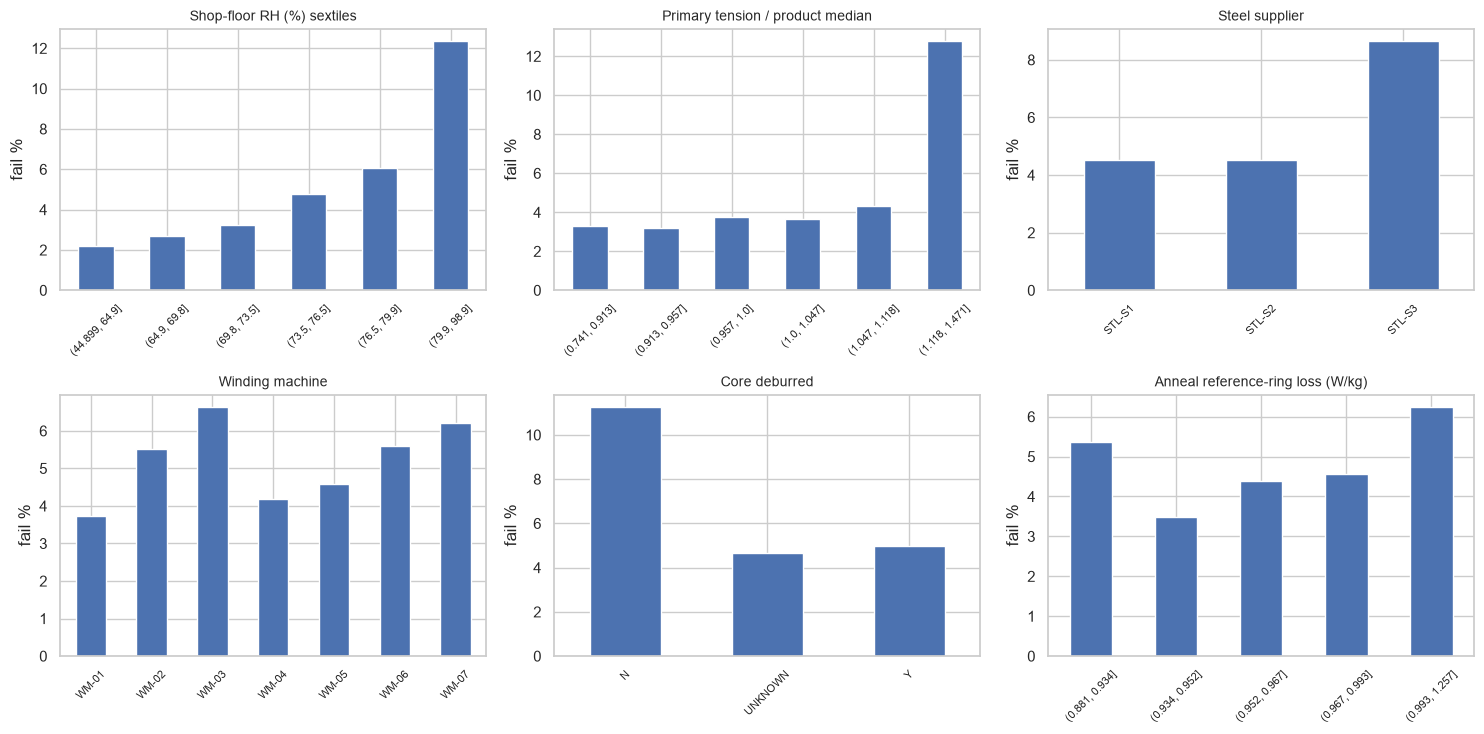

In [8]:
def rate_by(col, bins=None, ax=None, title=None):
    s = pd.qcut(fa[col], bins, duplicates="drop") if bins else fa[col]
    r = fa.groupby(s, observed=True).y_fail.mean()
    (r * 100).plot.bar(ax=ax, color="#4C72B0")
    ax.set_title(title or col, fontsize=10); ax.set_ylabel("fail %"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45, labelsize=8)

tmp = FeatureBuilder().fit(fa).transform(fa)
fa["_pri_tension_rel"] = tmp.pri_tension_rel
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
rate_by("winding_area_RH_pct", 6, axes[0, 0], "Shop-floor RH (%) sextiles")
rate_by("_pri_tension_rel", 6, axes[0, 1], "Primary tension / product median")
rate_by("steel_supplier", None, axes[0, 2], "Steel supplier")
rate_by("winding_machine", None, axes[1, 0], "Winding machine")
rate_by("core_deburred", None, axes[1, 1], "Core deburred")
rate_by("anneal_ref_ring_loss_W_kg", 5, axes[1, 2], "Anneal reference-ring loss (W/kg)")
fa.drop(columns="_pri_tension_rel", inplace=True)
savefig("04_bivariate")

## 4. Leakage control and feature engineering

**Leakage.** Every test-station column (IR, hipot, surge, DCR, no-load, OCV) and the outcome columns (`fail_code`, `disposition`, remarks) are measured *during* the predicted event, so they are removed. Identifiers are removed too, and so are `work_order` and `anneal_batch_id`, which are always new in future production.

**Engineered features** (`FeatureBuilder`, fitted on training data only):

| Feature | Meaning |
|---|---|
| `wip_hold_h` | hours between winding and test (moisture uptake) |
| `anneal_to_wind_days` | core storage time after annealing |
| `pri/sec_turn_dev` | logged − target turns (CNC machines) |
| `sec_turn_step_pct` | ratio change caused by one secondary turn |
| `pri/sec_tension_rel`, `pri/sec_speed_rel` | tension / speed relative to the product's median recipe |
| `core_mass_rel` | core mass vs product median (stacking factor) |
| `cert_loss_rel_grade` | coil certificate loss vs grade median |
| `inproc_dcr_rel` | in-process primary DCR vs product median |
| `core_section_mm2` | core cross-section from measured dimensions |

In [9]:
print(f"{len(CAT_FEATURES)} categorical + {len(NUM_FEATURES)} numeric + {len(ENGINEERED)} engineered = {len(FEATURES)} features")
print("excluded (leakage):", LEAKAGE_COLS)

16 categorical + 28 numeric + 13 engineered = 57 features
excluded (leakage): ['test_station', 'test_attempt', 'test_ambient_C', 'test_voltage_V', 'ir_Mohm', 'hipot_kV', 'hipot_leak_mA', 'surge_EAR_pct', 'pri_dcr_ohm', 'sec_dcr_ohm', 'noload_current_mA', 'noload_loss_W', 'noload_current_limit_mA', 'noload_loss_limit_W', 'sec_ocv_V', 'ocv_spec_V', 'ocv_error_pct', 'result', 'fail_code', 'disposition', 'operator_remarks']


## 5. Time-based train / validation / test split

The data is split by **winding date**:

| Split | Period | Use |
|---|---|---|
| Train | 01-Sep-2025 – 31-May-2026 | fit models |
| Validation | June 2026 | threshold, early stopping for benchmarks |
| Rolling-origin folds | train < Apr → val Apr–May; train < Jun → val Jun | RuleFit hyper-parameter selection |
| Test | July – August 2026 | final, untouched evaluation |

After selection, the final models are refitted on **train + validation** (Sep 2025 – Jun 2026) and scored once on the test period.

In [10]:
tr = fa[fa.wind_end_ts < "2026-06-01"].copy()
va = fa[(fa.wind_end_ts >= "2026-06-01") & (fa.wind_end_ts < "2026-07-01")].copy()
te = fa[fa.wind_end_ts >= "2026-07-01"].copy()
trva = pd.concat([tr, va])
pd.DataFrame({s: {"units": len(d), "fails": int(d.y_fail.sum()), "fail rate": f"{d.y_fail.mean():.2%}",
                  "from": d.wind_end_ts.min().date(), "to": d.wind_end_ts.max().date()}
              for s, d in [("train", tr), ("validation", va), ("test", te)]}).T

,units,fails,fail rate,from,to
train,9257,369,3.99%,2025-09-01,2026-05-30
validation,1219,132,10.83%,2026-06-01,2026-06-30
test,2289,159,6.95%,2026-07-01,2026-08-29


## 6. RuleFit

### 6.1 How the algorithm works

RuleFit (Friedman & Popescu, 2008, *Annals of Applied Statistics* 2(3)) builds the model

$$\operatorname{logit} P(\text{fail}\mid x) \;=\; a_0 \;+\; \sum_{k=1}^{K} a_k\, r_k(x) \;+\; \sum_{j=1}^{p} b_j\, \ell_j(x_j)$$

in three steps:

1. **Rule generation.** A randomised tree ensemble is grown (the paper's ISLE procedure):
   * each tree sees a random half of the data;
   * the number of leaves is drawn from an exponential distribution, giving a mix of short and long rules;
   * each tree is fitted to the residuals left by the previous trees and added with a small memory parameter ν.

   **Every node of every tree defines one rule**, $r_k(x)\in\{0,1\}$, e.g. `winding_area_RH_pct > 76 and pri_tension_rel > 1.11`. Depth is capped at 3, so a rule has at most 3 conditions. Rules with support < 0.5 % and duplicate rules are removed.
2. **Linear terms.** Each numeric feature also enters linearly, as $\ell_j(x_j)$: winsorised at the 2.5 / 97.5 % quantiles and scaled by $0.4/\sigma_j$ to match the typical spread of a rule.
3. **Sparse fit.** The coefficients $a_k, b_j$ come from an **L1-penalised (lasso) logistic regression**. The penalty $C$ sets most coefficients exactly to 0, keeping only a few dozen rules and terms out of ~1,500 candidates.

The trees are used only to *propose* rules. The prediction comes from the sparse linear model over those rules, not from trees voting or adding up.

### 6.2 How RuleFit differs from the models in the lectures

| | Decision tree | Random Forest / bagging | Gradient boosting (XGBoost, CatBoost) | Logistic / Lasso regression | **RuleFit** |
|---|---|---|---|---|---|
| Model form | one hierarchy of splits | average of hundreds of deep trees | sum of hundreds of trees | linear in the raw features | **sparse linear model over IF-THEN rules + linear terms** |
| Interactions | yes (hierarchy) | yes | yes | only if added by hand | yes, each rule is an interaction of ≤ 3 conditions |
| Smooth / linear effects | poor (step functions) | poor | poor | yes | yes (linear terms) |
| Interpretability | readable if shallow, unstable | black box | black box (needs SHAP) | coefficients | **the whole model is a short, ranked rule list with odds ratios** |
| Stability | high variance | stable | stable | stable | stable (rules pooled from many trees; lasso selects) |
| Complexity control | depth | n trees, depth | n trees, depth, learning rate | C | **C directly sets the number of rules** |

In manufacturing, a model the process engineer can audit and turn into work instructions is worth more than a small gain in AUC.

### 6.3 Implementation

`rulefit.py` is written for this project with scikit-learn building blocks:
* `DecisionTreeRegressor` for the ISLE rule generator;
* `decision_path` to evaluate rules quickly;
* `LogisticRegression(l1_ratio=1, solver="liblinear")` for the lasso step.

It adds three things for this data: missing values get their own branch, categoricals are one-hot encoded with rare levels grouped into `OTHER`, and the class probabilities are proper logistic probabilities.

### 6.4 Hyper-parameter selection (rolling-origin validation)

| Hyper-parameter | Grid | Meaning |
|---|---|---|
| `memory_par` (ν) | 0.1, 0.3 | how strongly each tree corrects the previous ones (rule diversity) |
| `mean_leaves` | 4, 6 | average tree size → average rule length |
| `C` | 0.01, 0.02, 0.04, 0.08 | inverse L1 strength → number of rules kept |
| `class_weight` | none, balanced | re-weighting of the 5 % minority class |

Selection criterion: mean **PR-AUC** over the two rolling-origin folds. Then the **parsimony rule**: among configurations within 0.01 PR-AUC of the best, take the one with the fewest terms.

In [11]:
folds = [("2026-04-01", "2026-06-01"), ("2026-06-01", "2026-07-01")]
rows, t0 = [], time.time()
for k, (a, b) in enumerate(folds):
    f_tr, f_va = fa[fa.wind_end_ts < a], fa[(fa.wind_end_ts >= a) & (fa.wind_end_ts < b)]
    fbk = FeatureBuilder().fit(f_tr)
    Xa, Xb = fbk.transform(f_tr), fbk.transform(f_va)
    for mp in [0.1, 0.3]:
        for L in [4, 6]:
            rf = RuleFitClassifier(n_trees=400, mean_leaves=L, memory_par=mp, random_state=SEED).fit(Xa, f_tr.y_fail, CAT_FEATURES)
            for C in [0.01, 0.02, 0.04, 0.08]:
                for cw in [None, "balanced"]:
                    rf.fit_lasso(C, cw)
                    p = rf.predict_proba(Xb)[:, 1]
                    rows.append(dict(fold=k + 1, memory_par=mp, mean_leaves=L, C=C, class_weight=str(cw),
                                     n_terms=rf.n_terms_, pr_auc=average_precision_score(f_va.y_fail, p),
                                     roc_auc=roc_auc_score(f_va.y_fail, p)))
grid = pd.DataFrame(rows)
sel = (grid.groupby(["memory_par", "mean_leaves", "C", "class_weight"])
           .agg(pr_auc=("pr_auc", "mean"), roc_auc=("roc_auc", "mean"), n_terms=("n_terms", "mean"))
           .reset_index().sort_values("pr_auc", ascending=False).reset_index(drop=True))
best_pr = sel.pr_auc.max()
chosen = sel[sel.pr_auc >= best_pr - 0.01].sort_values("n_terms").iloc[0]
rf_params = dict(memory_par=float(chosen.memory_par), mean_leaves=int(chosen.mean_leaves))
rf_C, rf_cw = float(chosen.C), (None if chosen.class_weight == "None" else chosen.class_weight)
print(f"{len(grid)} fits in {time.time()-t0:.0f}s")
print("selected:", rf_params, "C =", rf_C, "class_weight =", rf_cw, f"| mean val PR-AUC {chosen.pr_auc:.3f}, ~{chosen.n_terms:.0f} terms")
sel.head(12).round(3)

64 fits in 298s
selected: {'memory_par': 0.3, 'mean_leaves': 4} C = 0.04 class_weight = None | mean val PR-AUC 0.216, ~24 terms


,memory_par,mean_leaves,C,class_weight,pr_auc,roc_auc,n_terms
0,0.3,4,0.08,None,0.224,0.709,56.0
1,0.3,6,0.08,None,0.221,0.703,69.5
2,0.3,6,0.04,None,0.220,0.704,28.5
3,0.1,6,0.04,balanced,0.219,0.709,160.5
4,0.3,4,0.01,balanced,0.217,0.703,31.5
5,0.3,6,0.02,balanced,0.217,0.710,88.0
6,0.3,4,0.02,balanced,0.216,0.701,70.0
7,0.3,4,0.04,None,0.216,0.698,24.0
8,0.1,4,0.04,balanced,0.215,0.708,131.0
9,0.1,4,0.08,None,0.212,0.706,56.0


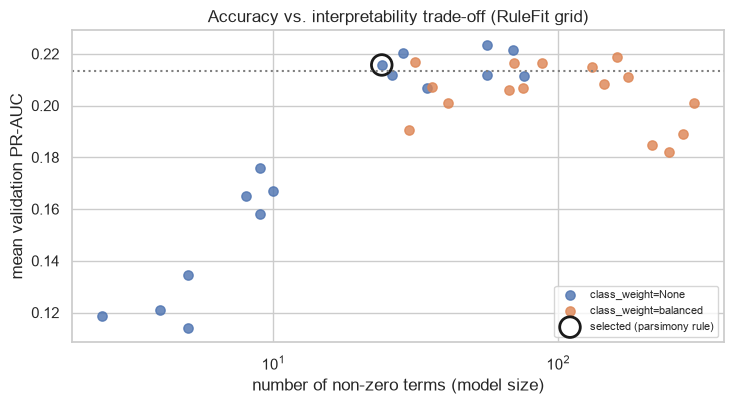

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for cw, g in sel.groupby("class_weight"):
    ax.scatter(g.n_terms, g.pr_auc, s=45, label=f"class_weight={cw}", alpha=0.8)
ax.scatter([chosen.n_terms], [chosen.pr_auc], s=220, facecolors="none", edgecolors="k", lw=2, label="selected (parsimony rule)")
ax.axhline(best_pr - 0.01, ls=":", color="grey")
ax.set_xscale("log"); ax.set_xlabel("number of non-zero terms (model size)"); ax.set_ylabel("mean validation PR-AUC")
ax.set_title("Accuracy vs. interpretability trade-off (RuleFit grid)"); ax.legend(fontsize=8)
savefig("05_rulefit_complexity")

### 6.5 Decision threshold (validation month)

The model outputs a failure probability, and the plant needs a cut-off for the action: a quick in-process hipot / surge / turns check before final taping. We assume a **missed failure costs 10×** a precautionary check, since finding it after final assembly means stripping, rewinding or scrapping. The threshold that minimises expected cost on **June 2026** (model trained on data up to May) is fixed and carried to the test period.

validation: ROC-AUC 0.737, PR-AUC 0.330; threshold = 0.0680


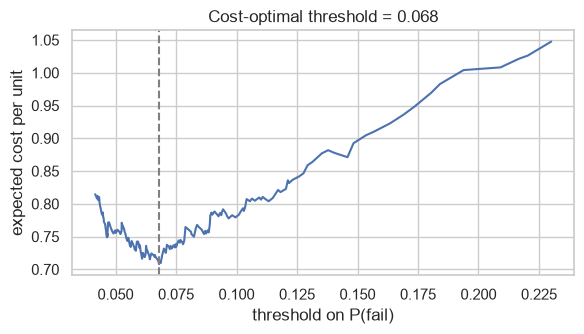

In [13]:
fb_tr = FeatureBuilder().fit(tr)
Xtr, Xva = fb_tr.transform(tr), fb_tr.transform(va)
rf_val = RuleFitClassifier(n_trees=400, random_state=SEED, C=rf_C, class_weight=rf_cw, **rf_params).fit(Xtr, tr.y_fail, CAT_FEATURES)
p_val = rf_val.predict_proba(Xva)[:, 1]
C_MISS, C_CHECK = 10.0, 1.0
ths = np.unique(np.quantile(p_val, np.linspace(0.30, 0.995, 200)))
cost = [(C_MISS * ((p_val < t) & (va.y_fail == 1)).sum() + C_CHECK * (p_val >= t).sum()) / len(va) for t in ths]
thr = float(ths[int(np.argmin(cost))])
print(f"validation: ROC-AUC {roc_auc_score(va.y_fail, p_val):.3f}, PR-AUC {average_precision_score(va.y_fail, p_val):.3f}; threshold = {thr:.4f}")
plt.figure(figsize=(6, 3.5)); plt.plot(ths, cost); plt.axvline(thr, ls="--", color="grey")
plt.xlabel("threshold on P(fail)"); plt.ylabel("expected cost per unit"); plt.title(f"Cost-optimal threshold = {thr:.3f}")
savefig("06_threshold_cost")

## 7. Benchmarks from the course

All benchmarks are refitted on Sep 2025 – Jun 2026 and scored on the same test period:

* **Logistic Regression:** L2, class-balanced. Preprocessing: median imputation with missing indicators, standardisation, one-hot encoding.
* **Random Forest:** 600 trees, `min_samples_leaf=5`, balanced subsamples.
* **CatBoost:** gradient boosting with ordered target statistics; depth 4, learning rate 0.06, `l2_leaf_reg` 10, `SqrtBalanced` weights. Tuned in an earlier experiment; the number of trees comes from early stopping on June.

In [14]:
fb = FeatureBuilder().fit(trva)
X_trva, X_test = fb.transform(trva), fb.transform(te)
y_trva, yte = trva.y_fail.values, te.y_fail.values
NUMS = NUM_FEATURES + ENGINEERED
def make_pre():
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUMS),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20), CAT_FEATURES)])
test_pred, models = {}, {}
t0 = time.time()
models["Logistic Regression"] = make_pipeline(make_pre(), LogisticRegression(C=0.3, class_weight="balanced", max_iter=5000)).fit(X_trva, y_trva)
models["Random Forest"] = make_pipeline(make_pre(), RandomForestClassifier(n_estimators=600, min_samples_leaf=5, max_features="sqrt",
                                        class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)).fit(X_trva, y_trva)
cb_params = dict(depth=4, learning_rate=0.06, l2_leaf_reg=10.0, auto_class_weights="SqrtBalanced")
cb_es = CatBoostClassifier(allow_writing_files=False, iterations=3000, eval_metric="PRAUC", od_type="Iter", od_wait=200, random_seed=SEED, verbose=0, **cb_params)
cb_es.fit(Pool(Xtr, tr.y_fail, cat_features=CAT_FEATURES), eval_set=Pool(Xva, va.y_fail, cat_features=CAT_FEATURES), use_best_model=True)
cb_iter = int(max(150, cb_es.get_best_iteration() * 1.15))
models["CatBoost"] = CatBoostClassifier(allow_writing_files=False, iterations=cb_iter, random_seed=SEED, verbose=0, **cb_params).fit(
    Pool(X_trva, y_trva, cat_features=CAT_FEATURES))
for name, m in models.items():
    Xin = Pool(X_test, cat_features=CAT_FEATURES) if name == "CatBoost" else X_test
    test_pred[name] = m.predict_proba(Xin)[:, 1]
print(f"benchmarks trained in {time.time()-t0:.0f}s (CatBoost trees = {cb_iter})")

benchmarks trained in 37s (CatBoost trees = 215)


## 8. Final RuleFit model and evaluation on the test period (Jul–Aug 2026)

In [15]:
t0 = time.time()
rulefit = RuleFitClassifier(n_trees=400, random_state=SEED, C=rf_C, class_weight=rf_cw, **rf_params).fit(X_trva, y_trva, CAT_FEATURES)
test_pred = {"RuleFit": rulefit.predict_proba(X_test)[:, 1], **test_pred}
p_test = test_pred["RuleFit"]
print(f"RuleFit fitted in {time.time()-t0:.0f}s: {len(rulefit.rules_text_)} candidate rules -> "
      f"{rulefit.n_rules_} rules + {rulefit.n_terms_ - rulefit.n_rules_} linear terms kept")

summary = pd.DataFrame({k: scores(yte, v) for k, v in test_pred.items()}).T
yhat = (p_test >= thr).astype(int)
summary.loc["RuleFit", ["Precision@thr", "Recall@thr", "F1@thr"]] = [precision_score(yte, yhat), recall_score(yte, yhat), f1_score(yte, yhat)]
summary.loc["RuleFit", "model size"] = f"{rulefit.n_terms_} terms"
summary.loc["Logistic Regression", "model size"] = f"{models['Logistic Regression'][-1].coef_.size} coefs"
summary.loc["Random Forest", "model size"] = "600 trees"
summary.loc["CatBoost", "model size"] = f"{cb_iter} trees"
print(f"test units = {len(yte)}, failures = {yte.sum()} (base rate {yte.mean():.3f})")
summary.round(3)

RuleFit fitted in 29s: 1565 candidate rules -> 39 rules + 0 linear terms kept
test units = 2289, failures = 159 (base rate 0.069)


,ROC-AUC,PR-AUC,Brier,Precision@thr,Recall@thr,F1@thr,model size
RuleFit,0.787,0.291,0.058,0.146,0.767,0.245,39 terms
Logistic Regression,0.753,0.265,0.253,NaN,NaN,NaN,206 coefs
Random Forest,0.769,0.263,0.075,NaN,NaN,NaN,600 trees
CatBoost,0.781,0.304,0.084,NaN,NaN,NaN,215 trees


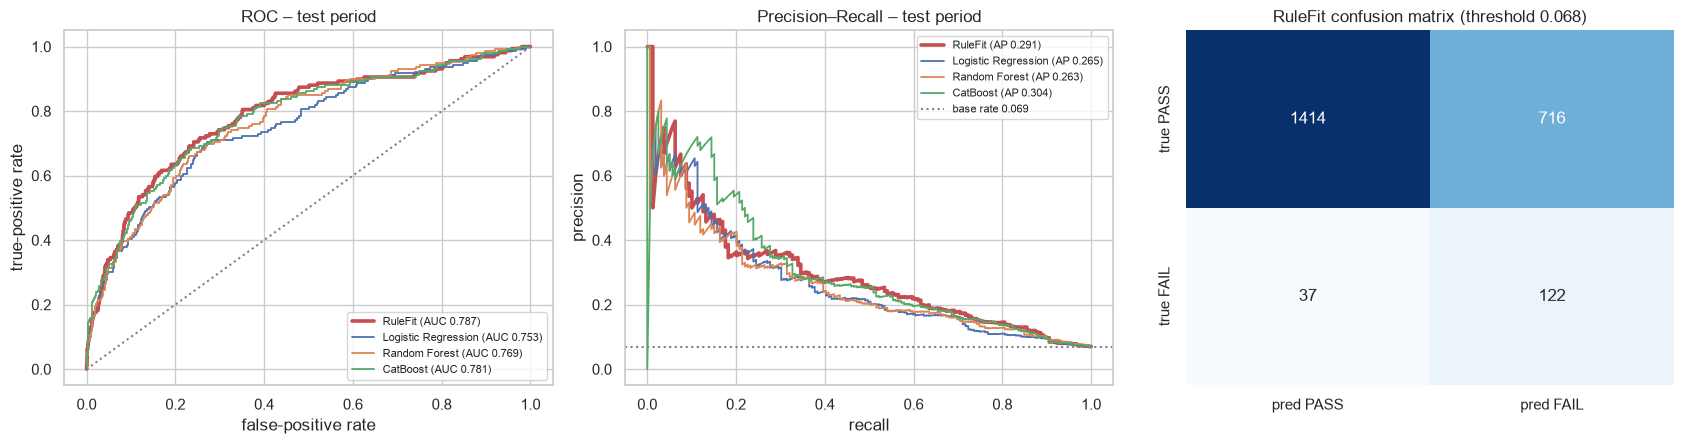

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
style = {"RuleFit": dict(lw=2.6, color="#C44E52")}
for name, p in test_pred.items():
    f, t, _ = roc_curve(yte, p); ax[0].plot(f, t, label=f"{name} (AUC {roc_auc_score(yte, p):.3f})", **style.get(name, dict(lw=1.3)))
    pr, rc, _ = precision_recall_curve(yte, p); ax[1].plot(rc, pr, label=f"{name} (AP {average_precision_score(yte, p):.3f})", **style.get(name, dict(lw=1.3)))
ax[0].plot([0, 1], [0, 1], ls=":", color="grey"); ax[0].set(title="ROC – test period", xlabel="false-positive rate", ylabel="true-positive rate")
ax[1].axhline(yte.mean(), ls=":", color="grey", label=f"base rate {yte.mean():.3f}")
ax[1].set(title="Precision–Recall – test period", xlabel="recall", ylabel="precision"); ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
cm = confusion_matrix(yte, yhat)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[2],
            xticklabels=["pred PASS", "pred FAIL"], yticklabels=["true PASS", "true FAIL"])
ax[2].set_title(f"RuleFit confusion matrix (threshold {thr:.3f})")
savefig("07_test_curves")

### 8.1 Operational view: capture rate when checking the riskiest units

In [17]:
def capture(y, p, fracs=(0.05, 0.10, 0.20, 0.30)):
    order = np.argsort(-p); out = {}
    for f in fracs:
        k = int(round(f * len(y))); hit = y[order[:k]].sum()
        out[f"top {int(f*100)}%"] = {"units checked": k, "failures caught": int(hit),
                                     "share of all failures": hit / y.sum(), "precision": hit / k, "lift": (hit / k) / y.mean()}
    return pd.DataFrame(out).T
cap = pd.concat({n: capture(yte, p)["share of all failures"] for n, p in test_pred.items()}, axis=1)
display(capture(yte, p_test).round(3))
print("share of all failures caught, by model:"); display(cap.round(3))

,units checked,failures caught,share of all failures,precision,lift
top 5%,114.0,40.0,0.252,0.351,5.051
top 10%,229.0,62.0,0.390,0.271,3.898
top 20%,458.0,98.0,0.616,0.214,3.080
top 30%,687.0,115.0,0.723,0.167,2.410


share of all failures caught, by model:


,RuleFit,Logistic Regression,Random Forest,CatBoost
top 5%,0.252,0.239,0.226,0.270
top 10%,0.390,0.371,0.390,0.396
top 20%,0.616,0.535,0.541,0.579
top 30%,0.723,0.698,0.692,0.698


### 8.2 Performance per failure mode (each mode vs all passing units)

In [18]:
per_mode = {}
for code_ in te.fail_code.unique():
    if code_ == "PASS": continue
    mk = te.fail_code.isin([code_, "PASS"]).values
    per_mode[code_] = {"test failures": int((te.fail_code == code_).sum()),
                       **{f"AUC {n}": roc_auc_score(yte[mk], p[mk]) for n, p in test_pred.items()},
                       "RuleFit recall@thr": yhat[(te.fail_code == code_).values].mean()}
pd.DataFrame(per_mode).T.sort_values("AUC RuleFit", ascending=False).round(3)

,test failures,AUC RuleFit,AUC Logistic Regression,AUC Random Forest,AUC CatBoost,RuleFit recall@thr
SURGE_SHORT,65.0,0.869,0.837,0.871,0.880,0.877
HIPOT_BD,36.0,0.791,0.721,0.719,0.735,0.833
NOLOAD_HIGH,19.0,0.722,0.661,0.718,0.717,0.579
IR_LOW,21.0,0.692,0.710,0.665,0.656,0.619
RATIO_OOT,18.0,0.657,0.656,0.673,0.727,0.611


### 8.3 Calibration

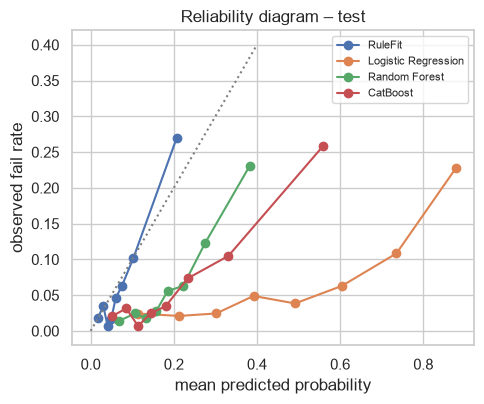

In [19]:
fig, ax = plt.subplots(figsize=(5, 4.2))
for name, p in test_pred.items():
    fp, mp_ = calibration_curve(yte, p, n_bins=8, strategy="quantile"); ax.plot(mp_, fp, marker="o", label=name)
ax.plot([0, 0.4], [0, 0.4], ls=":", color="grey"); ax.set(xlabel="mean predicted probability", ylabel="observed fail rate", title="Reliability diagram – test")
ax.legend(fontsize=8); savefig("08_calibration")

RuleFit without class weights is fitted by plain maximum likelihood, so its probabilities are close to calibrated. The class-weighted benchmarks (LR, RF, CatBoost) over-predict risk by design.

### 8.4 Robustness: stratified 5-fold cross-validation (random split)

The random split ignores time and lets every process event appear in training. It gives an optimistic upper reference next to the time-based test. The rule generator's randomness also shows up in the spread across folds.

In [20]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv = []
for k, (i_tr, i_te) in enumerate(skf.split(fa, fa.y_fail)):
    a, b = fa.iloc[i_tr], fa.iloc[i_te]
    fbk = FeatureBuilder().fit(a)
    mk = RuleFitClassifier(n_trees=400, random_state=SEED + k, C=rf_C, class_weight=rf_cw, **rf_params).fit(fbk.transform(a), a.y_fail, CAT_FEATURES)
    pk = mk.predict_proba(fbk.transform(b))[:, 1]
    cv.append({"fold": k + 1, "ROC-AUC": roc_auc_score(b.y_fail, pk), "PR-AUC": average_precision_score(b.y_fail, pk), "terms": mk.n_terms_})
cv = pd.DataFrame(cv).set_index("fold")
display(cv.round(3)); print("mean ± sd:", cv.mean().round(3).to_dict(), cv.std().round(3).to_dict())

,ROC-AUC,PR-AUC,terms
fold,,,
1,0.783,0.215,37
2,0.811,0.264,47
3,0.758,0.259,37
4,0.772,0.189,40
5,0.770,0.287,47


mean ± sd: {'ROC-AUC': 0.779, 'PR-AUC': 0.243, 'terms': 41.6} {'ROC-AUC': 0.02, 'PR-AUC': 0.04, 'terms': 5.079}


## 9. Explainability and interpretation

RuleFit is **intrinsically interpretable**: the fitted model *is* the rule list below. We add model-agnostic checks (permutation importance, PDP/ICE) and compare with SHAP explanations of the CatBoost benchmark.

### 9.1 The fitted model: rules and linear terms

* `coef` is the change in log-odds of failure when the rule fires (or per scaled unit, for linear terms).
* `odds_ratio` = exp(coef).
* `support` is the fraction of training units that satisfy the rule.
* `importance` = |coef| · √(s(1−s)), from Friedman & Popescu (2008), eq. 28.

In [21]:
rules = rulefit.get_rules()
print(f"intercept (log-odds) = {rulefit.intercept_:.3f}; {len(rules)} non-zero terms")
rules.round(3)

intercept (log-odds) = 0.049; 39 non-zero terms


,term,type,coef,odds_ratio,support,importance
0,pri_tension_rel <= 1.116 and steel_supplier != STL-S3 and winding_area_RH_pct <= 77.05,rule,-0.599,0.550,0.578,0.296
1,anneal_ref_ring_loss_W_kg <= 1.067 and pri_tension_rel <= 1.284 and winding_area_RH_pct <= 80.25,rule,-0.367,0.693,0.828,0.139
2,core_deburred != N and steel_supplier != STL-S3 and winding_area_RH_pct <= 79.15,rule,-0.316,0.729,0.747,0.137
3,pri_tension_N > 9.55 and pri_tension_rel <= 1.339 and winding_area_RH_pct > 72.15,rule,0.227,1.255,0.381,0.110
4,pri_speed_rel <= 1.091 and pri_speed_rel > 0.8838 and pri_tension_rel <= 1.358,rule,-0.272,0.761,0.809,0.107
5,pri_tension_rel <= 1.184 and winding_area_RH_pct <= 84.95,rule,-0.280,0.756,0.888,0.088
6,core_coat_thickness_um <= 170.5 and pri_tension_N > 11.45,rule,0.229,1.257,0.166,0.085
7,core_mass_g <= 8440 and pri_tension_rel <= 1.184,rule,-0.302,0.739,0.914,0.085
8,anneal_ref_ring_loss_W_kg <= 1.062 and pri_tension_N <= 70.15 and winding_area_RH_pct <= 84.95,rule,-0.320,0.726,0.926,0.084
9,anneal_dewpoint_C <= -19.3 and sec_speed_rel <= 1.149 and tape_overlap_pct > 44.5,rule,-0.197,0.821,0.840,0.072


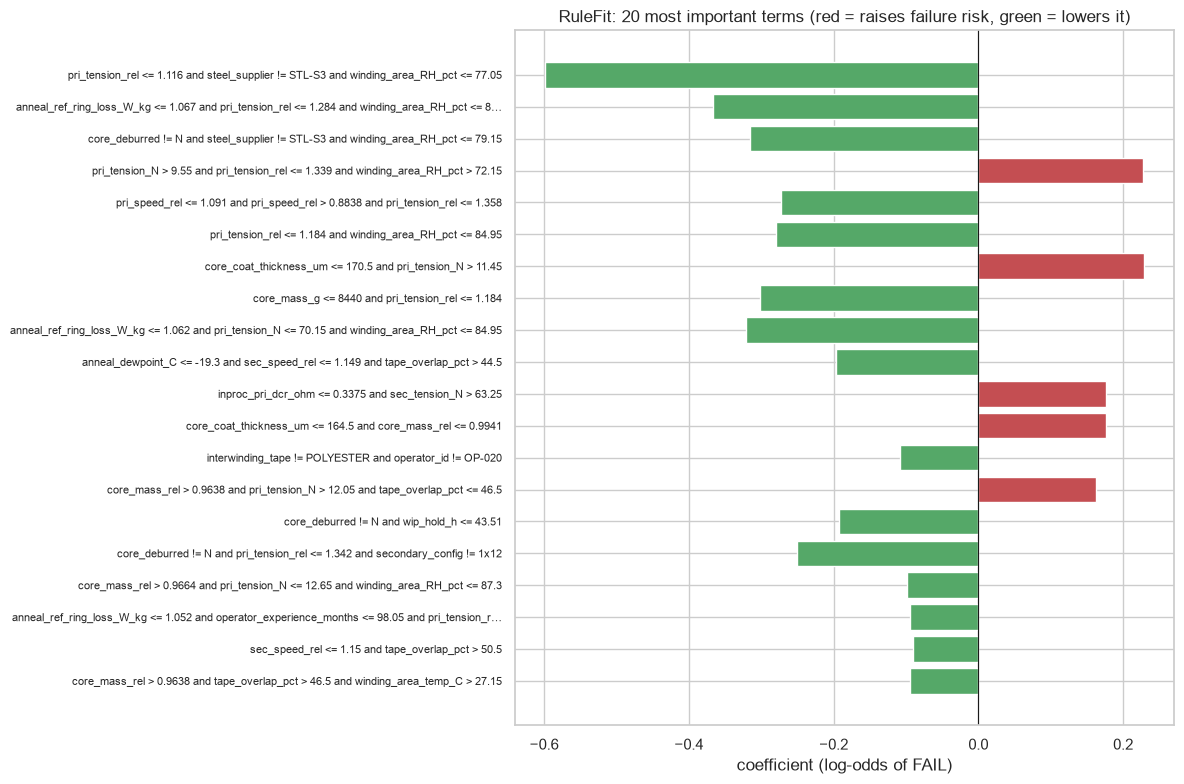

In [22]:
top = rules.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(12, 8))
colors = np.where(top.coef > 0, "#C44E52", "#55A868")
ax.barh(range(len(top)), top.coef, color=colors)
ax.set_yticks(range(len(top))); ax.set_yticklabels([t if len(t) < 95 else t[:92] + "…" for t in top.term], fontsize=8)
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("coefficient (log-odds of FAIL)")
ax.set_title("RuleFit: 20 most important terms (red = raises failure risk, green = lowers it)")
savefig("09_rulefit_rules")

**Reading the rules.** Most retained rules carry a *negative* coefficient. They describe the **safe operating window**: tension near the recipe, humidity below about 76 %, adequate tape overlap, steel not from STL-S3. A unit that falls **outside** the window loses these protective terms, so its risk rises. This is how a process engineer sets control limits, so the rules can be converted directly into control-plan limits or interlocks.

The intercept is close to 0 (P ≈ 0.5). This means *a unit that satisfies none of the safe-window rules has roughly a coin-flip chance of failing*. Every protective rule it satisfies lowers that risk, and the few positive rules (e.g. high RH combined with high tension, or thin epoxy coat) raise it again. Averaged over production, the predicted risk matches the observed fail rate (Section 8.3).

### 9.2 Global feature importance (Friedman & Popescu eq. 35)

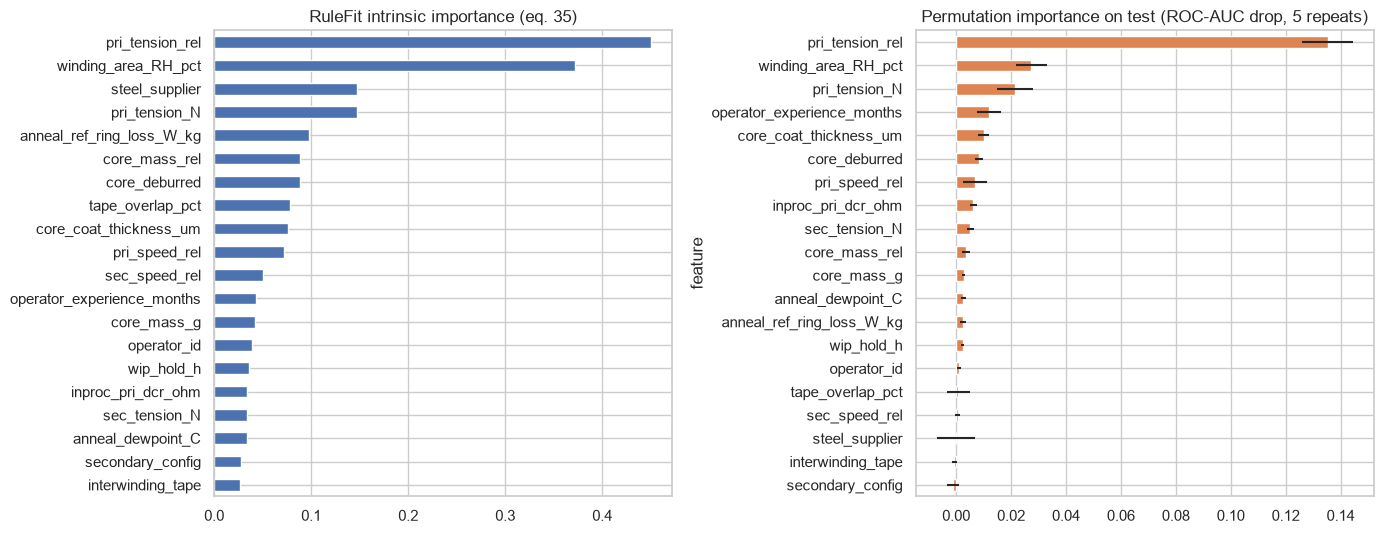

In [23]:
fi = rulefit.feature_importance()
fi = fi[fi > 0]
perm_rows = []
rng = np.random.default_rng(SEED)
base_auc = roc_auc_score(yte, p_test)
for f in fi.index[:20]:
    drops = []
    for r in range(5):
        Z = X_test.copy(); Z[f] = rng.permutation(Z[f].values)
        drops.append(base_auc - roc_auc_score(yte, rulefit.predict_proba(Z)[:, 1]))
    perm_rows.append((f, np.mean(drops), np.std(drops)))
perm = pd.DataFrame(perm_rows, columns=["feature", "AUC drop", "sd"]).set_index("feature")
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
fi.head(20)[::-1].plot.barh(ax=ax[0], color="#4C72B0"); ax[0].set_title("RuleFit intrinsic importance (eq. 35)")
perm["AUC drop"].sort_values().plot.barh(ax=ax[1], xerr=perm.sort_values("AUC drop")["sd"], color="#DD8452")
ax[1].set_title("Permutation importance on test (ROC-AUC drop, 5 repeats)")
savefig("10_feature_importance")

### 9.3 Partial dependence (PDP) and ICE curves

These show the predicted failure probability as one feature is swept while the others keep their observed values. We use 300 random test units; thin lines are ICE curves for individual units, the bold line is the PDP. Rules make the curves **step-shaped**, with each step at a rule threshold, and linear terms add slopes.

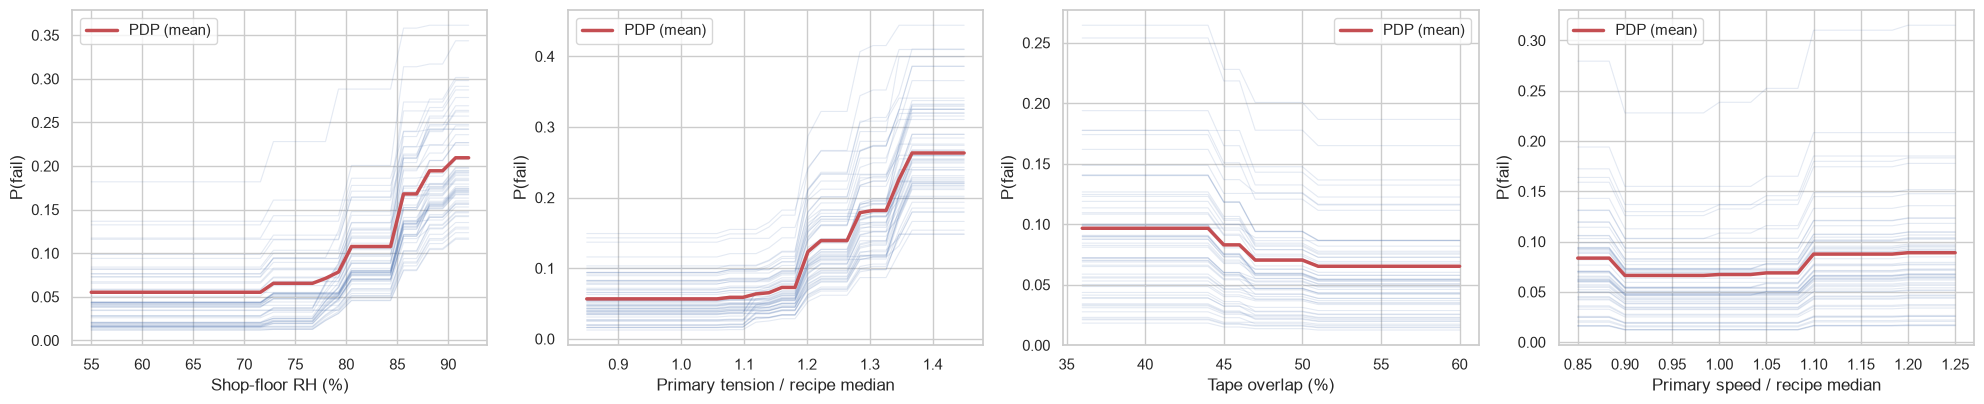

In [24]:
def pdp_ice(model, f, grid, n=300, ax=None, lab=None):
    smp = X_test.sample(n, random_state=SEED)
    ice = []
    for v in grid:
        Z = smp.copy(); Z[f] = v
        ice.append(model.predict_proba(Z)[:, 1])
    ice = np.array(ice).T
    ax.plot(grid, ice[:60].T, color="#4C72B0", alpha=0.15, lw=0.8)
    ax.plot(grid, ice.mean(0), color="#C44E52", lw=2.5, label="PDP (mean)")
    ax.set_xlabel(lab or f); ax.set_ylabel("P(fail)"); ax.legend()

fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
pdp_ice(rulefit, "winding_area_RH_pct", np.linspace(55, 92, 30), ax=axes[0], lab="Shop-floor RH (%)")
pdp_ice(rulefit, "pri_tension_rel", np.linspace(0.85, 1.45, 30), ax=axes[1], lab="Primary tension / recipe median")
pdp_ice(rulefit, "tape_overlap_pct", np.linspace(36, 60, 25), ax=axes[2], lab="Tape overlap (%)")
pdp_ice(rulefit, "pri_speed_rel", np.linspace(0.85, 1.25, 25), ax=axes[3], lab="Primary speed / recipe median")
savefig("11_pdp_ice")

### 9.4 Local explanations (individual units)

Because the model is additive in its terms, each prediction splits *exactly* into term contributions $a_k\,(r_k(x)-\bar r_k)$ and $b_j\,(\ell_j(x)-\bar\ell_j)$. Each rule's contribution is shared equally among the features it uses, giving per-feature contributions that sum to the unit's logit. These are the SHAP values of the rule-level linear model. For a unit we show the waterfall and the rules that fired.


highest-risk true failure: TT2607-010535 TT0160-2X115-2X35-60-A machine=WM-04 RH=80.3 -> P(fail)=0.509, actual=HIPOT_BD


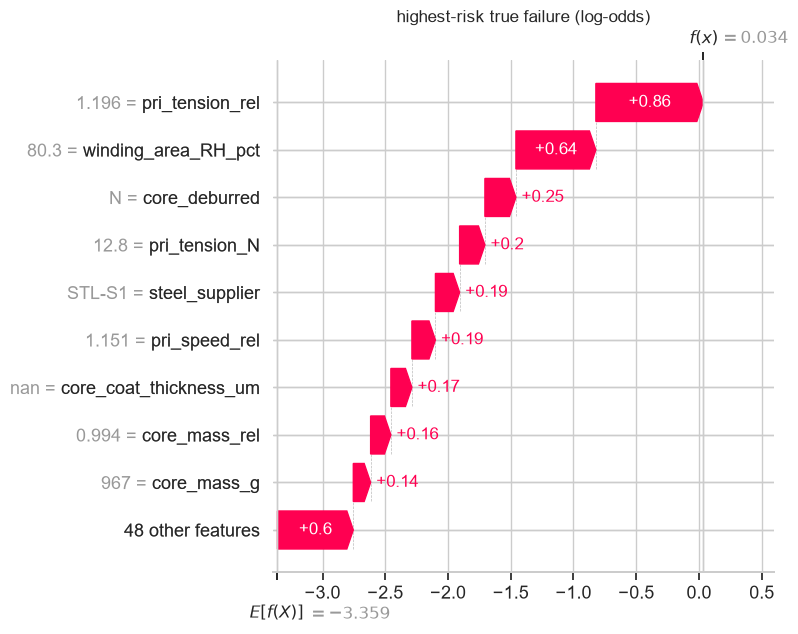


typical passing unit: TT2608-011937 TT0500-230-2X18-I machine=WM-06 RH=77.9 -> P(fail)=0.054, actual=PASS


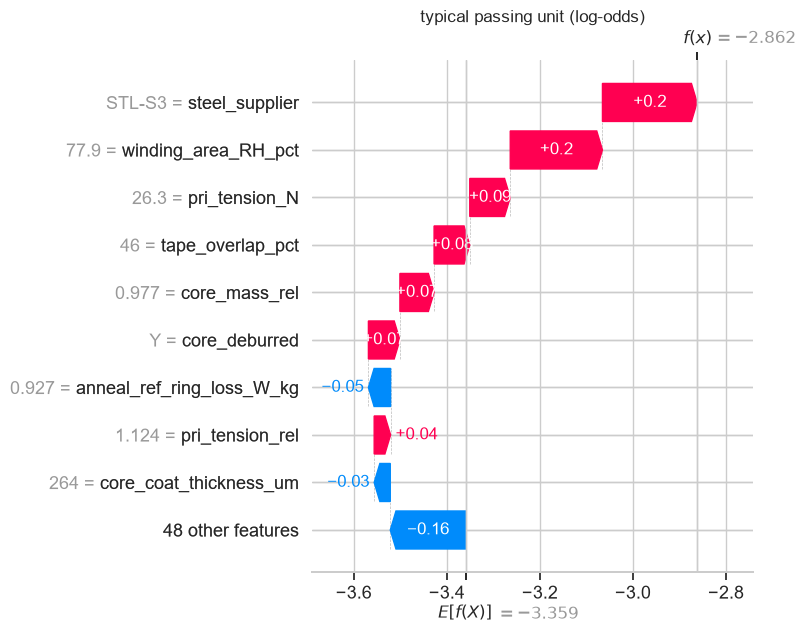

rules satisfied by the highest-risk failing unit:


,term,coef,odds_ratio,support
3,pri_tension_N > 9.55 and pri_tension_rel <= 1.339 and winding_area_RH_pct > 72.15,0.227,1.255,0.381
6,core_coat_thickness_um <= 170.5 and pri_tension_N > 11.45,0.229,1.257,0.166
8,anneal_ref_ring_loss_W_kg <= 1.062 and pri_tension_N <= 70.15 and winding_area_RH_pct <= 84.95,-0.320,0.726,0.926
9,anneal_dewpoint_C <= -19.3 and sec_speed_rel <= 1.149 and tape_overlap_pct > 44.5,-0.197,0.821,0.840
11,core_coat_thickness_um <= 164.5 and core_mass_rel <= 0.9941,0.176,1.192,0.178
13,core_mass_rel > 0.9638 and pri_tension_N > 12.05 and tape_overlap_pct <= 46.5,0.162,1.176,0.124
17,anneal_ref_ring_loss_W_kg <= 1.052 and operator_experience_months <= 98.05 and pri_tension_rel <= 1.339,-0.095,0.910,0.625
23,anneal_dewpoint_C <= -19.3 and pri_tension_rel <= 1.342 and steel_coil_lot != CL-2606-020,-0.126,0.882,0.945
24,interwinding_layers > 1.5 and pri_tension_rel <= 1.204,-0.097,0.907,0.937
26,pri_tension_rel > 1.075 and sec_wind_speed_rpm > 254.5,0.045,1.046,0.230


In [25]:
LC, base_logit = rulefit.local_contributions(X_test)
assert np.allclose(LC.sum(1).values + base_logit, rulefit.decision_function(X_test))
i_fail = int(np.argmax(np.where(yte == 1, p_test, -1)))
i_pass = int(np.argmin(np.abs(p_test - np.median(p_test)) + (yte == 1)))
for i, tag in [(i_fail, "highest-risk true failure"), (i_pass, "typical passing unit")]:
    row = te.iloc[i]
    print(f"\n{tag}: {row.serial_no} {row.product_code} machine={row.winding_machine} RH={row.winding_area_RH_pct} "
          f"-> P(fail)={p_test[i]:.3f}, actual={row.fail_code}")
    e = shap.Explanation(values=LC.iloc[i].values, base_values=base_logit, data=X_test.iloc[i].values, feature_names=list(X_test.columns))
    shap.plots.waterfall(e, max_display=10, show=False); plt.title(f"{tag} (log-odds)"); savefig(f"12_waterfall_{'fail' if i == i_fail else 'pass'}")
fired = rulefit.active_rules(X_test.iloc[[i_fail]])
print("rules satisfied by the highest-risk failing unit:")
fired[["term", "coef", "odds_ratio", "support"]].round(3) if len(fired) else "none"

### 9.5 Which features drive each failure mode?

The model is trained on a single PASS/FAIL target. Averaging the local contributions of the true failures in each mode shows whether it has learned mode-specific mechanisms.

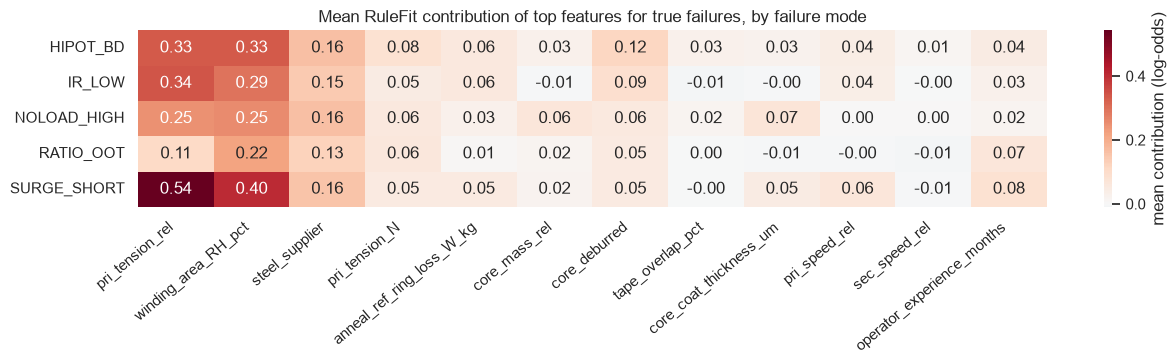

In [26]:
topf = fi.index[:12]
by_mode = LC.loc[:, topf].groupby(te.fail_code.values).mean().drop(index="PASS")
plt.figure(figsize=(13, 3.8))
sns.heatmap(by_mode, cmap="RdBu_r", center=0, annot=True, fmt=".2f", cbar_kws={"label": "mean contribution (log-odds)"})
plt.title("Mean RuleFit contribution of top features for true failures, by failure mode"); plt.xticks(rotation=40, ha="right")
savefig("13_contrib_by_mode")

### 9.6 Cross-check with SHAP on the black-box benchmark (CatBoost)

If an interpretable model and a black box trained on the same data rank the same drivers, we can be more confident that the explanation reflects the data and not one model's artefacts.

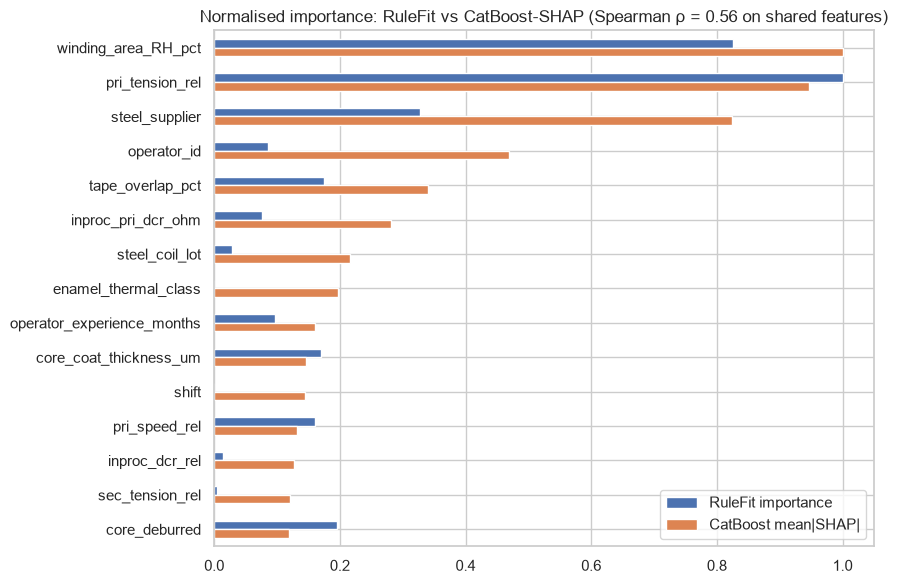

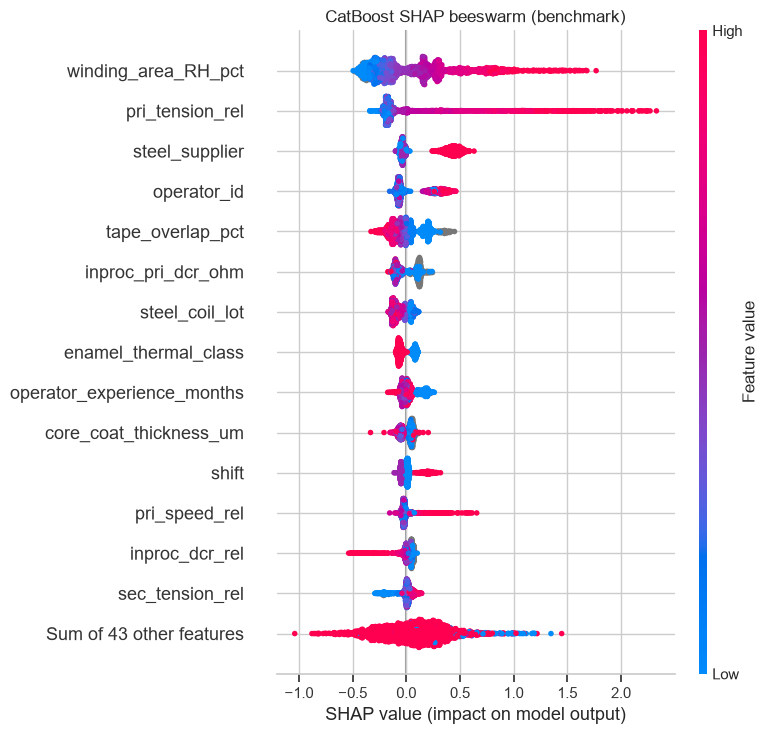

In [27]:
cb = models["CatBoost"]
sv = cb.get_feature_importance(Pool(X_test, yte, cat_features=CAT_FEATURES), type="ShapValues")[:, :-1]
shap_imp = pd.Series(np.abs(sv).mean(0), index=X_test.columns)
comp = pd.DataFrame({"RuleFit importance": fi.reindex(X_test.columns).fillna(0), "CatBoost mean|SHAP|": shap_imp})
comp = comp[(comp > 0).any(axis=1)]
rho = comp.rank().corr(method="spearman").iloc[0, 1]
top_union = comp.sort_values("CatBoost mean|SHAP|", ascending=False).head(15)
(top_union / top_union.max()).plot.barh(figsize=(9, 6)); plt.gca().invert_yaxis()
plt.title(f"Normalised importance: RuleFit vs CatBoost-SHAP (Spearman ρ = {rho:.2f} on shared features)")
savefig("14_rulefit_vs_shap")
X_plot = X_test.copy()
for c in CAT_FEATURES: X_plot[c] = X_plot[c].astype("category").cat.codes
shap.plots.beeswarm(shap.Explanation(sv, np.zeros(len(sv)), X_plot.values, feature_names=list(X_test.columns)),
                    max_display=15, show=False); plt.title("CatBoost SHAP beeswarm (benchmark)"); savefig("15_catboost_shap_beeswarm")

### 9.7 Process-event check (WM-05 guide-roller wear)

One known process event can be checked here: winding machine WM-05's guide roller wore from mid-May until its service on 14-Jul-2026. Its units should show higher predicted risk during that window, because they were wound at higher tension and speed. Shown here: in-sample predictions on all units, by week.

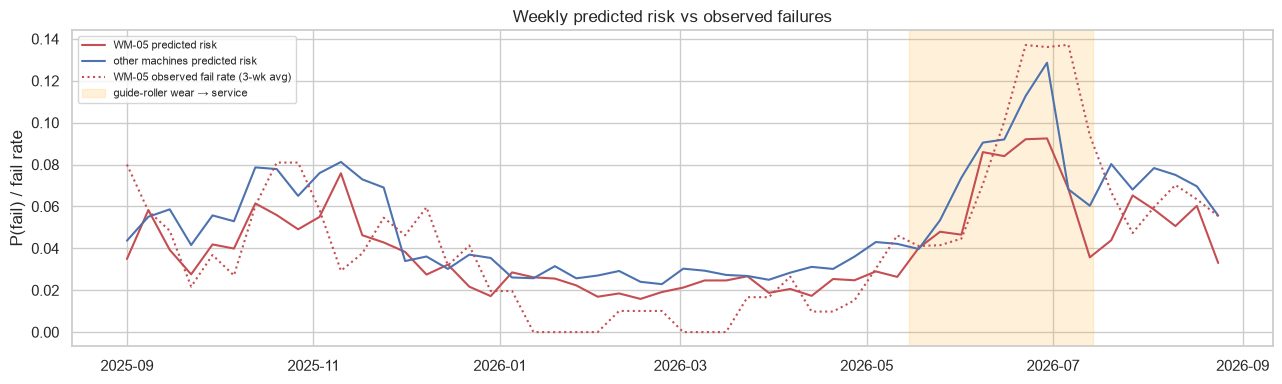

In [28]:
X_all = fb.transform(fa)
p_all = rulefit.predict_proba(X_all)[:, 1]
wk = fa.wind_end_ts.dt.to_period("W").dt.start_time
risk = pd.DataFrame({"week": wk, "WM-05": fa.winding_machine.eq("WM-05"), "p": p_all, "y": fa.y_fail})
pw = risk.groupby(["week", "WM-05"]).agg(pred=("p", "mean"), obs=("y", "mean")).unstack()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(pw.index, pw[("pred", True)], label="WM-05 predicted risk", color="#C44E52")
ax.plot(pw.index, pw[("pred", False)], label="other machines predicted risk", color="#4C72B0")
ax.plot(pw.index, pw[("obs", True)].rolling(3, min_periods=1).mean(), ls=":", color="#C44E52", label="WM-05 observed fail rate (3-wk avg)")
ax.axvspan(pd.Timestamp("2026-05-15"), pd.Timestamp("2026-07-14"), color="orange", alpha=0.15, label="guide-roller wear → service")
ax.set_ylabel("P(fail) / fail rate"); ax.legend(fontsize=8); ax.set_title("Weekly predicted risk vs observed failures")
savefig("16_event_check")

**Interpretation.** Predicted risk follows the observed failure rate over the year: the Oct–Nov humidity peak, the dry Dec–Apr period and the June peak. During the wear window, however, WM-05's **observed** fail rate (≈ 14 %) clearly exceeds its **predicted** risk (≈ 9 %), and the gap closes after the 14-Jul service.

Guide-roller wear is not recorded by any sensor in the dataset, so the model cannot see it directly. This is a limitation, but also a use case: **monitoring the gap between observed and predicted failures per machine** works as a residual-based early-warning signal. A predictive-maintenance sensor (roller vibration or wire-guide friction) would be a valuable new feature.

### 9.8 Domain-knowledge alignment

| Physical mechanism (toroidal transformer engineering) | Expected | Learned by RuleFit |
|---|---|---|
| Excess wire tension / winding speed crack the enamel → shorted turns (surge-test fail) | risk ↑ above the recipe value | safe-window rules `pri_tension_rel ≤ ~1.1–1.2` and `pri_speed_rel ≤ ~1.1–1.2`; risk steps up above them (PDP) |
| Humid air weakens insulation → hipot breakdown, low IR | risk ↑ with RH, especially > 75 % | `winding_area_RH_pct ≤ ~72–80` appears in most rules and is the top feature |
| Low tape overlap / thin coating / undeburred core → insulation puncture | risk ↑ | `tape_overlap_pct > ~44` is protective; coat thickness and deburring appear with lower weight |
| High-loss steel lots / poor anneal → high magnetising current (no-load fail) | risk ↑ for supplier S3 and high ring loss | `steel_supplier != STL-S3` inside the safe-window rules |
| Manual turn counting / inexperienced operators → ratio slips | old machines, new operators | weak signal (`operator_id` terms); ratio failures stay hard to predict |

The sparse model concentrates on the two dominant, sensor-visible mechanisms: tension/speed and humidity/insulation. Rarer modes (no-load, ratio, IR contamination) are only partly captured, as the per-mode AUCs in 8.2 show. The CatBoost benchmark ranks the same top drivers.

## 10. Bias, fairness and robustness checks

`operator_id` and `operator_experience_months` relate to people. The checks below:
1. Compare performance across shifts and experience bands.
2. Retrain without operator features and measure the cost.

The goal is process improvement and training, not individual blame.

In [29]:
grp = pd.DataFrame({"y": yte, "p": p_test, "yhat": yhat, "shift": te["shift"].values,
                    "exp": pd.cut(te.operator_experience_months, [-1, 6, 24, 1e4], labels=["< 6 m", "6–24 m", "> 24 m"]).values})
def grp_stats(g):
    return pd.Series({"units": len(g), "fail rate": g.y.mean(), "ROC-AUC": roc_auc_score(g.y, g.p) if g.y.nunique() > 1 else np.nan,
                      "recall@thr": g.yhat[g.y == 1].mean(), "flag rate": g.yhat.mean()})
display(grp.groupby("shift").apply(grp_stats).round(3))
display(grp.groupby("exp", observed=True).apply(grp_stats).round(3))

,units,fail rate,ROC-AUC,recall@thr,flag rate
shift,,,,,
A,1215.0,0.064,0.784,0.744,0.342
B,751.0,0.056,0.718,0.619,0.308
C,323.0,0.121,0.842,0.974,0.594


,units,fail rate,ROC-AUC,recall@thr,flag rate
exp,,,,,
< 6 m,428.0,0.150,0.789,0.844,0.589
6–24 m,165.0,0.024,0.745,0.750,0.230
> 24 m,1673.0,0.054,0.760,0.714,0.322


In [30]:
no_op = [c for c in FEATURES if c not in ("operator_id", "operator_experience_months")]
rf_noop = RuleFitClassifier(n_trees=400, random_state=SEED, C=rf_C, class_weight=rf_cw, **rf_params).fit(
    X_trva[no_op], y_trva, [c for c in CAT_FEATURES if c in no_op])
p_noop = rf_noop.predict_proba(X_test[no_op])[:, 1]
pd.DataFrame({"with operator features": {**scores(yte, p_test), "terms": rulefit.n_terms_},
              "without operator features": {**scores(yte, p_noop), "terms": rf_noop.n_terms_}}).round(3)

,with operator features,without operator features
ROC-AUC,0.787,0.777
PR-AUC,0.291,0.264
Brier,0.058,0.058
terms,39.000,37.000


## 11. Save the model and metadata for the front-end

In [31]:
joblib.dump(rulefit.compact(), MODELS / "rulefit_eol.joblib")
fb.to_json(MODELS / "feature_builder.json")
rules.to_csv(MODELS / "rulefit_rules.csv", index=False)
meta = {
    "algorithm": "RuleFit (Friedman & Popescu 2008), own implementation rulefit.py",
    "features": FEATURES, "cat_features": CAT_FEATURES, "threshold": thr,
    "cost_miss": C_MISS, "cost_check": C_CHECK,
    "params": {**rf_params, "n_trees": 400, "C": rf_C, "class_weight": rf_cw, "max_depth": 3},
    "n_terms": rulefit.n_terms_, "n_rules": rulefit.n_rules_,
    "train_period": [str(trva.wind_end_ts.min().date()), str(trva.wind_end_ts.max().date())],
    "test_metrics": {m: {k: round(float(v), 4) for k, v in summary.loc[m].items() if isinstance(v, (int, float, np.floating)) and pd.notna(v)}
                     for m in summary.index},
    "cv_metrics": {k: round(float(v), 4) for k, v in cv.mean().items()},
}
(MODELS / "model_meta.json").write_text(json.dumps(meta, indent=1))
print(json.dumps(meta["test_metrics"], indent=1)); print("saved to", MODELS.resolve())

{
 "RuleFit": {
  "ROC-AUC": 0.7868,
  "PR-AUC": 0.2914,
  "Brier": 0.0576,
  "Precision@thr": 0.1456,
  "Recall@thr": 0.7673,
  "F1@thr": 0.2447
 },
 "Logistic Regression": {
  "ROC-AUC": 0.7525,
  "PR-AUC": 0.2654,
  "Brier": 0.2533
 },
 "Random Forest": {
  "ROC-AUC": 0.7686,
  "PR-AUC": 0.2628,
  "Brier": 0.0746
 },
 "CatBoost": {
  "ROC-AUC": 0.7809,
  "PR-AUC": 0.304,
  "Brier": 0.084
 }
}
saved to D:\PERSONAL\02_Education\MSc\Sem 02\IT5514 - Applied Machine Learning\AML\Code\models


## 12. Summary

* **Task:** predict first-pass EOL failure of toroidal transformers from upstream process data (12,765 units, 5.2 % failures, 57 features after leakage removal).
* **Algorithm:** RuleFit, a sparse rule ensemble not covered in the lectures. It was selected by rolling-origin validation with a parsimony rule and evaluated on a later, untouched two-month period.
* **Results:** Section 8 compares RuleFit with Logistic Regression, Random Forest and CatBoost on the same split, using ROC-AUC, PR-AUC, a cost-based threshold, capture rates, calibration and per-mode AUC.
* **Explainability:** the fitted rule list with odds ratios, Friedman importance, permutation importance, PDP/ICE, exact local decompositions, and a cross-check against CatBoost-SHAP. The learned rules match transformer physics (Section 9.8).
* **Limitations and ethics:** discussed in the report. In brief: there is concept drift, some root causes are unobservable, and operator features need care.